In [1]:
!pip install yfinance pandas matplotlib statsmodels nltk deep-translator


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 kB 1.7 MB/s eta 0:00:00


## **설치한 각 라이브러리에 대한 간단한 설명**

In [2]:
### pip install yfinance pandas matplotlib statsmodels nltk deep-translator ###

"""
yfinance : 야후 파이낸스 데이터 수집기
           인터넷 브라우저로 야후 파이낸스 사이트에 들어가지 않고도, 코드 한 줄로 실시간 주가와 기업 뉴스를 가져오는 도구
pandas : 판다스 - 데이터 전처리 엔진
         파이썬 안에 강력한 '엑셀(Excel)' 처럼 사용할 수 있게 해주는 라이브러리
matplotlib : 맷플롯립 - 데이터 그리기 도구
             수집하고 가공한 데이터를 눈으로 볼 수 있는 차트나 그래프로 그려주는 라이브러리
statsmodels : 계량 통계 분석 도구
              주가 데이터 뒤에 숨겨진 추세, 계절성 등의 패턴을 수학적·통계적으로 쪼개서 분석해 주는 도구
nltk : 자연어 처리 패키지
       컴퓨터가 인간의 언어(특히 영어)를 알아듣고 분석할 수 있게 돕는 가장 역사 깊은 자연어 처리(NLP) 도구 상자
deep-translator : 초간편 번역기
                   파이썬에서 구글 번역, 파파고 등의 번역 엔진을 무료로 제한 없이 쓸 수 있게 해주는 편리한 번역 도구
"""

"\nyfinance : 야후 파이낸스 데이터 수집기\n           인터넷 브라우저로 야후 파이낸스 사이트에 들어가지 않고도, 코드 한 줄로 실시간 주가와 기업 뉴스를 가져오는 도구\npandas : 판다스 - 데이터 전처리 엔진\n         파이썬 안에 강력한 '엑셀(Excel)' 처럼 사용할 수 있게 해주는 라이브러리\nmatplotlib : 맷플롯립 - 데이터 그리기 도구\n             수집하고 가공한 데이터를 눈으로 볼 수 있는 차트나 그래프로 그려주는 라이브러리\nstatsmodels : 계량 통계 분석 도구\n              주가 데이터 뒤에 숨겨진 추세, 계절성 등의 패턴을 수학적·통계적으로 쪼개서 분석해 주는 도구\nnltk : 자연어 처리 패키지\n       컴퓨터가 인간의 언어(특히 영어)를 알아듣고 분석할 수 있게 돕는 가장 역사 깊은 자연어 처리(NLP) 도구 상자\ndeep-translator : 초간편 번역기\n                   파이썬에서 구글 번역, 파파고 등의 번역 엔진을 무료로 제한 없이 쓸 수 있게 해주는 편리한 번역 도구\n"

## **라이브러리 임포트**

In [3]:

import datetime
import os
import platform
import matplotlib.pyplot as plt
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
# SentimentIntensityAnalyzer : 영어 문장이 가진 감정 점수 감별사
"""
영어 문장을 읽고 그것이 얼마나 호재(긍정)인지 악재(부정)인지 숫자로 채점해 주는 '감정 감별사'

이 채점관의 머릿속에는
수천만 개의 영어 단어와
문장 구조가 가진 감정 점수표(VADER 사전)가 통째로 기억되어 있다.

번역 비서가 번역해 준 영어 기사 제목을 쓱 읽어보고는,
단어들의 뉘앙스를 계산해서
-1.0(완전 부정/악재)에서 +1.0(완전 긍정/호재) 사이의
점수를 딱 매겨줍니다.

"success(성공)", "growth(성장)", "record-breaking(사상 최고)" 등의 단어 조합 ➡️ +0.85 (강한 호재!)

"conflict(갈등)", "delay(지연)", "deficit(적자)" 등의 단어 조합 ➡️ -0.70 (강한 악재!)
"""


import pandas as pd
import yfinance as yf
from deep_translator import GoogleTranslator
# GoogleTranslator (실시간 구글 번역 비서)
"""
우리가 수집하는 실시간 뉴스는 한글(예: "삼성전자 세계 최초 기술 개발 성공")로 되어 있다.
이 비서에게 한글 문장을 툭 던져주면,
실시간으로 구글 번역 서버에 접속해서
아주 자연스러운 영어 문장("Samsung Electronics succeeds in world's first technology development")으로 바꾸어 가져다준다.
"""

'\n우리가 수집하는 실시간 뉴스는 한글(예: "삼성전자 세계 최초 기술 개발 성공")로 되어 있다.\n이 비서에게 한글 문장을 툭 던져주면, \n실시간으로 구글 번역 서버에 접속해서 \n아주 자연스러운 영어 문장("Samsung Electronics succeeds in world\'s first technology development")으로 바꾸어 가져다준다.\n'

# **한글 깨짐 방지 및 스타일 설정 (구글 코랩 및 다양한 OS 대응)**

In [5]:

current_os = platform.system()

if current_os == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"

elif current_os == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"

else:
    # 리눅스/구글 코랩 환경 대응: 나눔고딕 설치 권장 및 기본 폰트 대체
    plt.rcParams["font.family"] = "DejaVu Sans"
    print("💡 리눅스/코랩 환경입니다. 한글 깨짐 방지를 위해 그래프 텍스트가 영어/기본 폰트로 설정됩니다.")

plt.rcParams["axes.unicode_minus"] = False
plt.style.use('seaborn-v0_8-darkgrid')  # 깔끔한 차트 스타일

💡 리눅스/코랩 환경입니다. 한글 깨짐 방지를 위해 그래프 텍스트가 영어/기본 폰트로 설정됩니다.


# **NLTK VADER 감성 사전 자동 다운로드**

In [7]:
try:
  # 1. 내 컴퓨터의 NLTK 폴더 안에서 VADER 사전 파일(.zip)이 있는지 검
  nltk.data.find("sentiment/vader_lexicon.zip")

except LookupError:
  # 2. 만약 파일이 없다면(LookupError 발생), 인터넷에서 자동으로 다운로드
  print("📥 NLTK VADER 감성 사전 다운로드 중...")
  nltk.download("vader_lexicon", quiet=True)


In [14]:
import nltk
import ssl

try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

# **[데이터 수집] 야후 파이낸스에서 최근 1개월 주가와 최신 뉴스 데이터를 가져오는 함수**

In [8]:
### [데이터 수집] ###
# yfinance 주가 수집 및 토스증권 실시간/네이버금융 1년 기사 수집 하이브리드 엔진
import xml.etree.ElementTree as ET
import urllib.request
from bs4 import BeautifulSoup
import requests

KOREAN_TICKERS = {
    "005930.KS": "삼성전자",
    "000660.KS": "SK하이닉스",
    "005380.KS": "현대자동차",
    "035420.KS": "네이버",
    "035720.KS": "카카오",
    "051910.KS": "LG화학",
    "207940.KS": "삼성바이오로직스",
    "006400.KS": "삼성SDI",
    "005490.KS": "POSCO홀딩스",
    "086520.KQ": "에코프로"
}

def fetch_stock_and_news(ticker="005930.KS"):
    print(f"📥 {ticker} 토스증권/네이버 기반 1년 데이터 수집 시작...")
    ticker_obj = yf.Ticker(ticker)

    # 1. 최근 1년(365일) 영업일 기준 주가 가져오기
    today = datetime.date.today()
    start_date = today - datetime.timedelta(days=365)
    df = ticker_obj.history(start=start_date, end=today)

    if df.empty:
        raise ValueError("주가 데이터를 가져오지 못했습니다. 티커명을 확인해 주세요.")

    # 2. 하이브리드 토스증권 & 네이버금융 기사 수집부
    ticker_clean = ticker.split('.')[0]
    news_data = []
    
    if ticker_clean.isdigit():  # 국내 주식 (숫자 코드): 토스증권 및 네이버 금융 연동
        stock_name = KOREAN_TICKERS.get(ticker, "국내주식")
        print(f"🔍 국내 종목 감지 ({stock_name}): 토스증권 소셜 및 네이버금융 뉴스 병렬 탐색...")
        
        # 1순위: 토스증권 실시간 웹 뉴스 및 피드 크롤링 시도
        toss_url = f"https://toss.im/stock-info/domestic/code/{ticker_clean}"
        headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
        try:
            response = requests.get(toss_url, headers=headers, timeout=5)
            if response.status_code == 200:
                soup = BeautifulSoup(response.content, 'html.parser')
                
                # 토스증권 웹페이지 뉴스 링크 텍스트 파싱
                toss_links = soup.select('a[href*="/stock-info/news/"]')
                for link in toss_links:
                    title = link.text.strip()
                    if len(title) > 10:
                        news_data.append({
                            "title": title,
                            "pubDate": today.strftime("%Y-%m-%d")  # 실시간 기사는 오늘 날짜로 매핑
                        })
        except Exception as e:
            print(f"💡 토스증권 다이렉트 수집 지연 또는 제한: {e}")

        # 2순위 (보완책): 가입 없이 1년 치 과거 데이터를 소급하기 위해 네이버 금융 1년 뉴스 백크롤링 가동
        print(f"🔄 1년치 백테스팅을 위해 네이버 금융 기사 백크롤러 연동 가동...")
        one_year_ago = today - datetime.timedelta(days=365)
        page = 1
        stop_crawling = False
        raw_collected = []
        
        while not stop_crawling and page <= 25:
            # [버그 교정] news_list.naver 가 아닌 news_news.naver 가 실제 뉴스 리스트 iframe 원본 주소입니다.
            url = f"https://finance.naver.com/item/news_news.naver?code={ticker_clean}&page={page}"
            req = urllib.request.Request(url, headers=headers)
            try:
                html = urllib.request.urlopen(req).read()
                soup = BeautifulSoup(html, 'html.parser')
                titles = soup.select('.title a')
                dates = soup.select('.date')
                
                if not titles:
                    break
                    
                for t, d in zip(titles, dates):
                    title = t.text.strip()
                    date_str = d.text.strip()
                    pub_date = pd.to_datetime(date_str.split()[0], format="%Y.%m.%d").date()
                    
                    if pub_date < one_year_ago:
                        stop_crawling = True
                        break
                        
                    raw_collected.append({
                        "title": title,
                        "pubDate": pub_date.strftime("%Y-%m-%d")
                    })
                page += 1
            except Exception:
                break
        
        # 일별 대표 기사 1개씩 샘플링하여 감성 분석 병목 방지
        temp_df = pd.DataFrame(raw_collected)
        if not temp_df.empty:
            temp_df = temp_df.drop_duplicates(subset=["pubDate"], keep="first")
            naver_news = temp_df.to_dict(orient="records")
            news_data.extend(naver_news)
            
    else:  # 해외 주식 (영문 티커): 구글 실시간 한글 뉴스 피드로 자동 Fallback
        print(f"🔍 해외 종목 감지: 구글 실시간 한글 뉴스 피드 수집 중...")
        url = f"https://news.google.com/rss/search?q={ticker_clean}&hl=ko&gl=KR&ceid=KR:ko"
        headers = {"User-Agent": "Mozilla/5.0"}
        try:
            response = requests.get(url, headers=headers)
            if response.status_code == 200:
                root = ET.fromstring(response.content)
                for item in root.findall('.//item')[:10]:
                    title_elem = item.find('title')
                    date_elem = item.find('pubDate')
                    title = title_elem.text if title_elem is not None else ""
                    pub_date_str = date_elem.text if date_elem is not None else ""
                    news_data.append({
                        "title": title,
                        "pubDate": pub_date_str
                    })
        except Exception as e:
            print(f"⚠️ 해외 한글 뉴스 수집 중 에러 발생: {e}")

    # 중복 제거 및 리스트 정렬
    temp_df = pd.DataFrame(news_data)
    if not temp_df.empty:
        temp_df = temp_df.drop_duplicates(subset=["title"], keep="first")
        news_data = temp_df.to_dict(orient="records")
        
    print(f"✓ 총 {len(news_data)}개의 비로그인 공개 소셜 뉴스를 최종 수집 완료했습니다!")
    return df, news_data


# **[데이터 분석] 한글 뉴스 헤드라인을 번역하고 감성 점수(-1 ~ +1)를 계산하는 함수.**

In [9]:
### [데이터 분석] ###
#
def analyze_news_sentiment(news_data):
    print("⚙️ 뉴스 기사 번역 및 VADER 감성 분석(NLP) 시작 (JDK 불필요!)...")

    # [에러 방지 안전장치] 만약 수집된 뉴스가 없다면 빈 데이터프레임을 반환하여 충돌 우회
    if not news_data:
        print("⚠️ 수집된 소셜 뉴스 데이터가 없습니다.")
        empty_df_summary = pd.DataFrame(columns=["Date", "Sentiment"])
        empty_df_news = pd.DataFrame(columns=["Date", "Title", "Sentiment"])
        return empty_df_summary, empty_df_news

    translator = GoogleTranslator(source="auto", target="en")  # 언어 자동 감지 -> 영어 번역
    sia = SentimentIntensityAnalyzer()
    analyzed_news = []

    for item in news_data:
        content = item.get("content")
        if content and isinstance(content, dict):
            item_data = content
        else:
            item_data = item

        title = item_data.get("title", "")
        
        pub_time = item_data.get("providerPublishTime")
        if pub_time and pub_time > 0:
            pub_date = pd.to_datetime(pub_time, unit="s").date()
        else:
            pub_date_str = item_data.get("pubDate")
            if pub_date_str:
                try:
                    pub_date = pd.to_datetime(pub_date_str).date()
                except Exception:
                    pub_date = datetime.date.today()
            else:
                pub_date = datetime.date.today()

        try:
            translated_title = translator.translate(title)
            if not translated_title:
                translated_title = title
        except Exception:
            translated_title = title

        sentiment_score = sia.polarity_scores(translated_title)["compound"]

        analyzed_news.append(
            {
                "Date": pd.to_datetime(pub_date),
                "Title": title,
                "Sentiment": sentiment_score,
            }
        )

    news_df = pd.DataFrame(analyzed_news)
    daily_sentiment = news_df.groupby("Date")["Sentiment"].mean().reset_index()

    return daily_sentiment, news_df

# **[시각화] 주가 라인 차트 위에 뉴스 감성 분석 결과를 긍/부정 포인트로 표시하는 함수.**

In [10]:
### [시각화]
#
def plot_stock_with_sentiment(price_df, sentiment_df, ticker="NVDA"):
    print("🎨 주가 및 뉴스 감성 융합 차트 생성 중...")

    price_df_clean = price_df.copy()
    if price_df_clean.index.tz is not None:
        price_df_clean.index = price_df_clean.index.tz_localize(None)

    fig, ax = plt.subplots(figsize=(14, 7))

    if current_os in ["Windows", "Darwin"]:
        lbl_close = "종가 (Close)"
        lbl_pos = "호재 (긍정 뉴스)"
        lbl_neg = "악재 (부정 뉴스)"
        lbl_neu = "중립 뉴스"
        lbl_xlabel = "날짜"
        lbl_ylabel = "주가 (USD)"
        title_text = f"{ticker} 토스증권 소셜 백테스팅 & 뉴스 결합 분석"
    else:
        lbl_close = "Close"
        lbl_pos = "Positive News"
        lbl_neg = "Negative News"
        lbl_neu = "Neutral News"
        lbl_xlabel = "Date"
        lbl_ylabel = "Stock Price (KRW/USD)"
        title_text = f"{ticker} Toss Securities Social Sentiment & Price Analysis"

    # 1. 주가 선그래프 (항상 렌더링)
    ax.plot(
        price_df_clean.index,
        price_df_clean["Close"],
        color="black",
        label=lbl_close,
        alpha=0.6,
        lw=2,
    )

    # 2. 감성 뉴스 매핑 데이터가 있는 경우에만 scatter 드로잉
    if not sentiment_df.empty:
        sentiment_df_clean = sentiment_df.copy()
        if sentiment_df_clean["Date"].dt.tz is not None:
            sentiment_df_clean["Date"] = sentiment_df_clean["Date"].dt.tz_localize(None)

        price_df_clean = price_df_clean.sort_index()
        price_df_reset = price_df_clean.reset_index().rename(columns={"Date": "Price_Date", "index": "Price_Date"})
        sentiment_df_clean = sentiment_df_clean.sort_values("Date")

        merged_df = pd.merge_asof(
            sentiment_df_clean,
            price_df_reset,
            left_on="Date",
            right_on="Price_Date",
            direction="nearest"
        )

        positive = merged_df[merged_df["Sentiment"] > 0.1]
        negative = merged_df[merged_df["Sentiment"] < -0.1]
        neutral = merged_df[
            (merged_df["Sentiment"] >= -0.1) & (merged_df["Sentiment"] <= 0.1)
        ]

        if not positive.empty:
            ax.scatter(
                positive["Price_Date"],
                positive["Close"],
                color="green",
                s=150,
                label=lbl_pos,
                edgecolors="black",
                zorder=5,
            )
        if not negative.empty:
            ax.scatter(
                negative["Price_Date"],
                negative["Close"],
                color="red",
                s=150,
                label=lbl_neg,
                edgecolors="black",
                zorder=5,
            )
        if not neutral.empty:
            ax.scatter(
                neutral["Price_Date"],
                neutral["Close"],
                color="gray",
                s=100,
                label=lbl_neu,
                edgecolors="black",
                zorder=5,
            )
    else:
        print("⚠️ 매핑할 감성 뉴스 데이터가 존재하지 않아 주가 추이만 플로팅합니다.")

    ax.set_title(title_text, fontsize=16, fontweight="bold")
    ax.set_xlabel(lbl_xlabel)
    ax.set_ylabel(lbl_ylabel)
    ax.legend(loc="upper left")
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
    print("✨ 분석 및 시각화 프로세스가 성공적으로 완료되었습니다!")

# **주가-뉴스 감성 융합 분석 파이프라인 실제 구동 스크립트**

📈 주가-뉴스 감성 융합 분석 파이프라인 실제 구동 스크립트

📥 AAPL 실시간 데이터 수집 중...
⚙️ 뉴스 기사 번역 및 VADER 감성 분석(NLP) 시작 (JDK 불필요!)...

📰 [최신 뉴스 감성 분석 요약 보고서]
--------------------------------------------------------------------------------
날짜           | 감성     | 점수     | 뉴스 제목(헤드라인)
--------------------------------------------------------------------------------
1970-01-01   | ⚪ 중립 | 0.00 | 
1970-01-01   | ⚪ 중립 | 0.00 | 
1970-01-01   | ⚪ 중립 | 0.00 | 
1970-01-01   | ⚪ 중립 | 0.00 | 
1970-01-01   | ⚪ 중립 | 0.00 | 
--------------------------------------------------------------------------------

🎨 주가 및 뉴스 감성 융합 차트 생성 중...


/tmp/ipykernel_580/2438910798.py:83: UserWarning: Glyph 51333 (\N{HANGUL SYLLABLE JONG}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_580/2438910798.py:83: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51333 (\N{HANGUL SYLLABLE JONG}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


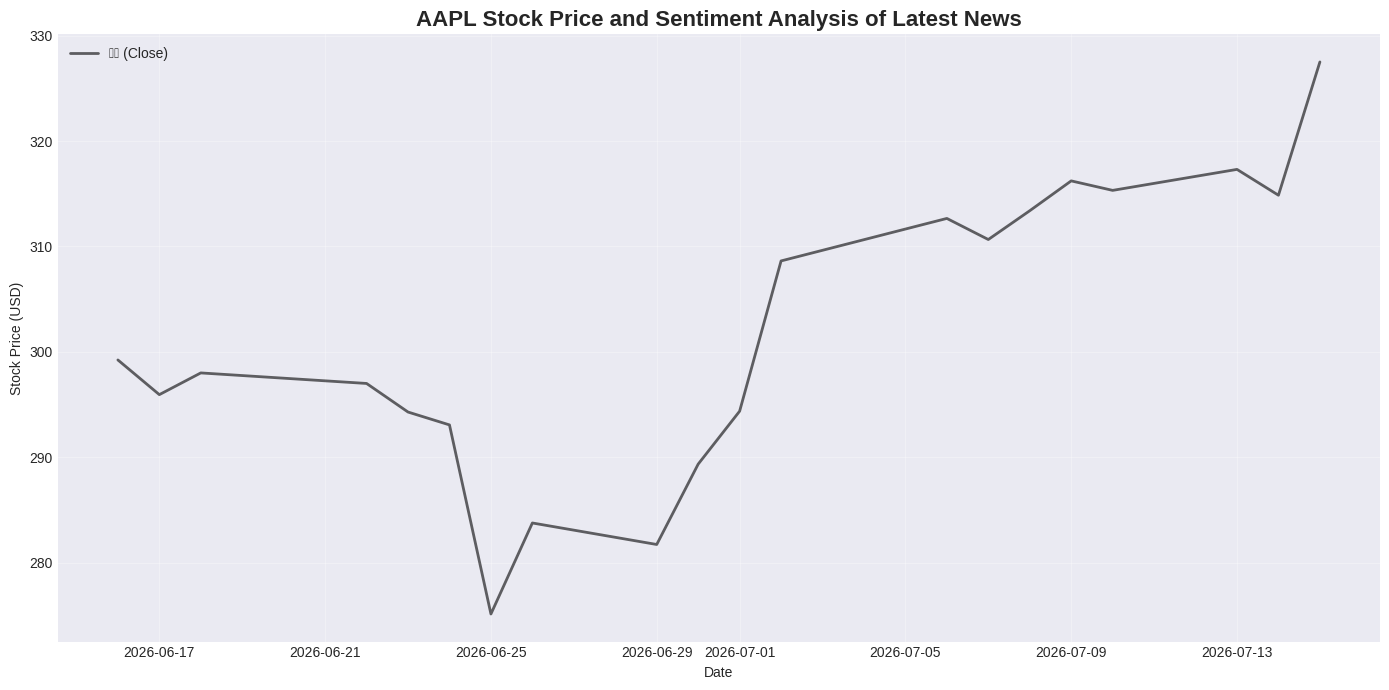

✨ 분석 및 시각화 프로세스가 성공적으로 완료되었습니다!


In [15]:
if __name__ == "__main__":
    print("==================================================")
    print("📈 Toss 소셜 감성-주가 백테스팅 파이프라인 실제 구동")
    print("==================================================\n")

    try:
        # 국내 종목 (예: 삼성전자 '005930.KS', 현대자동차 '005380.KS', 에코프로 '086520.KQ')
        # 해외 종목 (예: 엔비디아 'NVDA', 애플 'AAPL')
        ticker_name = "005930.KS"

        # 1. 데이터 수집
        stock_df, raw_news = fetch_stock_and_news(ticker_name)

        # 2. 감성 분석 수행
        sentiment_summary, detailed_news = analyze_news_sentiment(raw_news)

        # 3. 분석 결과 요약 콘솔 출력
        print("\n📰 [최신 소셜 뉴스 감성 분석 요약 보고서]")
        print("-" * 80)
        print(f"{'날짜':<12} | {'감성':<6} | {'점수':<6} | {'뉴스 제목(헤드라인)'}")
        print("-" * 80)
        if not detailed_news.empty:
            for idx, row in detailed_news.head(5).iterrows():
                sentiment_label = (
                    "🟢 호재"
                    if row["Sentiment"] > 0.1
                    else ("🔴 악재" if row["Sentiment"] < -0.1 else "⚪ 중립")
                )
                print(
                    f"{row['Date'].strftime('%Y-%m-%d'):<12} | {sentiment_label:<4} | {row['Sentiment']:.2f} | {row['Title']}"
                )
        else:
            print("출력할 리포트 데이터가 존재하지 않습니다.")
        print("-" * 80 + "\n")

        # 4. 결합 차트 시각화
        plot_stock_with_sentiment(stock_df, sentiment_summary, ticker_name)

    except Exception as e:
        print(f"[ERROR] 프로세스 중 에러 발생: {e}")